# Sequential Data and Recurrent Neural Networks

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as snss
import pandas as pd
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['figure.dpi'] = 150

In [2]:
# Check available hardware
import torch
if torch.cuda.is_available():
    print(f'GPU is available, using GPU {torch.cuda.get_device_name(0)}')
    device = torch.device('cuda')
elif torch.mps.is_available():
    print(f'Apple Metal Performance Shaders framework is available, using {torch.device("mps")}')
    device = torch.device('mps')
else:
    print(f'Hardware acceleration not available, using CPU')
    device = torch.device('cpu')

GPU is available, using GPU Tesla T4


## Example with toy sequences

In [3]:
x_seq = torch.FloatTensor([[1,], [2,], [3,]])
x_seq = x_seq.repeat(1, 2)
print(f"x_seq has shape {x_seq.shape} which means it is a sequence of {x_seq.shape[0]} {x_seq.shape[1]}-dimensional vectors")

x_seq has shape torch.Size([3, 2]) which means it is a sequence of 3 2-dimensional vectors


An RNN has a hidden state $h^{(t)}$ which receives two inputs: 

- the previous hidden state $h^{(t-1)}$
- the current input $x^{(t)}$

In [4]:
import torch.nn as nn
import torch.nn.functional as F

class RNN_Cell(nn.Module):
    def __init__(self, input_size=2, hidden_size=4):
        super().__init__()

        self.hidden_size = hidden_size

        # Weight and bias connecting previous hidden state
        self.w_hh = nn.Parameter(torch.randn(size=(hidden_size, hidden_size)))
        self.b_hh = nn.Parameter(torch.zeros(hidden_size))
        
        # Weight and bias connecting inputs
        self.w_ih = nn.Parameter(torch.randn(size=(hidden_size, input_size)))
        self.b_ih = nn.Parameter(torch.zeros(hidden_size))

    def forward(self, x):
        """ x has size [B, t, c]
        """
        B, T, C = x.shape
        ht = torch.zeros([B, self.hidden_size], device=x.device, dtype=x.dtype)
        ot = torch.zeros([B, T, self.hidden_size], device=x.device, dtype=x.dtype)
        for t in range(T):
            xt = x[:, t, :]
            print(f'At t = {t}')
            print(f'\tInput = {xt.numpy()}')
            zt = xt @ self.w_ih.T + self.b_ih + \
                 ht @ self.w_hh.T + self.b_hh
            ht = F.tanh(zt)
            print(f'\tHidden = {ht.detach().numpy()}')
            ot[:, t, :] = ht

        return ot, ht
            
torch_RNN = nn.RNN(input_size=2, hidden_size=4, batch_first=True)
print("Ground truth")
print("------------")
output, hidden = torch_RNN(x_seq[None])
print(f"Output is of size {output.shape}")
print(output)
print()
print(f"Last hidden is of size {hidden.shape}")
print(hidden)

print()
print("Our implementation")
print("------------------")
np.set_printoptions(precision=4)
cell = RNN_Cell()
with torch.no_grad():
    cell.w_hh[:] = torch_RNN.weight_hh_l0
    cell.b_hh[:] = torch_RNN.bias_hh_l0
    cell.w_ih[:] = torch_RNN.weight_ih_l0
    cell.b_ih[:] = torch_RNN.bias_ih_l0

output, hidden = cell(x_seq[None])

print()
print(f"Output is of size {output.shape}")
print(output)
print()
print(f"Last hidden is of size {hidden.shape}")
print(hidden)       

Ground truth
------------
Output is of size torch.Size([1, 3, 4])
tensor([[[-0.6960, -0.5402,  0.3262,  0.1280],
         [-0.9285, -0.4426,  0.7586,  0.1111],
         [-0.9771, -0.4285,  0.8652,  0.3533]]], grad_fn=<TransposeBackward1>)

Last hidden is of size torch.Size([1, 1, 4])
tensor([[[-0.9771, -0.4285,  0.8652,  0.3533]]], grad_fn=<StackBackward0>)

Our implementation
------------------
At t = 0
	Input = [[1. 1.]]
	Hidden = [[-0.696  -0.5402  0.3262  0.128 ]]
At t = 1
	Input = [[2. 2.]]
	Hidden = [[-0.9285 -0.4426  0.7586  0.1111]]
At t = 2
	Input = [[3. 3.]]
	Hidden = [[-0.9771 -0.4285  0.8652  0.3533]]

Output is of size torch.Size([1, 3, 4])
tensor([[[-0.6960, -0.5402,  0.3262,  0.1280],
         [-0.9285, -0.4426,  0.7586,  0.1111],
         [-0.9771, -0.4285,  0.8652,  0.3533]]], grad_fn=<CopySlices>)

Last hidden is of size torch.Size([1, 4])
tensor([[-0.9771, -0.4285,  0.8652,  0.3533]], grad_fn=<TanhBackward0>)


## Classification example: IMDB sentiment database

In [5]:
!pip install pyarrow==15.0.2 datasets==4.0.0 transformers==5.0.0 numpy==1.26.4

In [6]:
from datasets import load_dataset

imdb_dataset = load_dataset("stanfordnlp/imdb")

In [7]:
imdb_dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

In [8]:
from torch.utils.data import Dataset, random_split, DataLoader

class IMDBDataset(Dataset):
    def __init__(self, hf_data):
        self.hf_data = hf_data

    def __len__(self):
        return len(self.hf_data)

    def __getitem__(self, idx):
        return {
            'text': self.hf_data[idx]['text'],
            'label': self.hf_data[idx]['label']
        }

train_val_dataset = IMDBDataset(imdb_dataset['train'])
train_dataset, val_dataset = random_split(train_val_dataset, lengths=[0.8, 0.2])

loader = DataLoader(train_dataset, batch_size=1, shuffle=True)
batch = next(iter(loader))
print(batch['text'], batch['label'])

['This is a very funny movie! I have no idea whether it translates well into other languages or not. However, I do think men all over the world can identify with "Frank" and his thoughts to some extent! These thoughts are hugely entertaining and women will also enjoy this movie I\'m sure!<br /><br />All cast members perform well, and this film could have been a tremendous hit all over the world if it was made in England or the US. But for those of you who are fortunate enough to understand Swedish, you are in for a treat!<br /><br />Highly recommended.'] tensor([1])


In [10]:
train_val_dataset = imdb_dataset['train']
train_dataset, val_dataset = random_split(train_val_dataset, lengths=[0.8, 0.2])
test_dataset = imdb_dataset['test']

loader = DataLoader(train_dataset, batch_size=1, shuffle=True)
batch = next(iter(loader))
print(batch['text'], batch['label'])

["in this movie, joe pesci slams dunks a basketball. joe pesci...<br /><br />and being consistent, the rest of the script is equally not believable.<br /><br />pesci is a funny guy, which saves this film from sinking int the absolute back of the cellar, but the other roles were pretty bad. the father was a greedy businessman who valued money more than people, which wasn't even well-played. instead of the man being an archetypal villain, he seemed more like an amoral android programmed to make money at all costs. then there's the token piece that is assigned to pesci as a girlfriend or something...i don't even remember...she was that forgettable.<br /><br />anyone who rates this movie above a 5 or 6 is a paid member of some sort of film studio trying to up the reputation of this sunken film, or at least one of those millions of media minions who can't critique efficiently (you know, the people who feel bad if they give anything a mark below 6).<br /><br />stay away...far away. and shame

### Preprocessing each sample

#### Tokenization

In [15]:
import re
def tokenize(sentence):
    # Remove HTML tags - anything that starts with <, ends with >, and doesn't contain a > inside
    sentence = re.sub('<[^>]*>', '', sentence)

    # Emoticon processing
    emoticons = re.findall('(?::|;|=)(?:-)?(?:\)|\(|D|P)', sentence.lower())

    # Standardize all whitespace and append emoticons to make sentiment processing easier
    sentence = re.sub('[\W]+', ' ', sentence.lower()) + ' '.join(emoticons).replace('-', '')

    return sentence.split()

text = '  your  :-) text   here <br/> :-)'
tokenize(text)

['your', 'text', 'here', ':)', ':)']

In [16]:
tokenize(batch['text'][0])

['in',
 'this',
 'movie',
 'joe',
 'pesci',
 'slams',
 'dunks',
 'a',
 'basketball',
 'joe',
 'pesci',
 'and',
 'being',
 'consistent',
 'the',
 'rest',
 'of',
 'the',
 'script',
 'is',
 'equally',
 'not',
 'believable',
 'pesci',
 'is',
 'a',
 'funny',
 'guy',
 'which',
 'saves',
 'this',
 'film',
 'from',
 'sinking',
 'int',
 'the',
 'absolute',
 'back',
 'of',
 'the',
 'cellar',
 'but',
 'the',
 'other',
 'roles',
 'were',
 'pretty',
 'bad',
 'the',
 'father',
 'was',
 'a',
 'greedy',
 'businessman',
 'who',
 'valued',
 'money',
 'more',
 'than',
 'people',
 'which',
 'wasn',
 't',
 'even',
 'well',
 'played',
 'instead',
 'of',
 'the',
 'man',
 'being',
 'an',
 'archetypal',
 'villain',
 'he',
 'seemed',
 'more',
 'like',
 'an',
 'amoral',
 'android',
 'programmed',
 'to',
 'make',
 'money',
 'at',
 'all',
 'costs',
 'then',
 'there',
 's',
 'the',
 'token',
 'piece',
 'that',
 'is',
 'assigned',
 'to',
 'pesci',
 'as',
 'a',
 'girlfriend',
 'or',
 'something',
 'i',
 'don',
 't',


#### Vocabulary building

In [19]:
from collections import Counter
from tqdm import tqdm

def build_vocab_counts(dataset):
    vocab = Counter()
    for sample in tqdm(dataset):
        tokens = tokenize(sample['text'])
        vocab.update(tokens)
    return vocab

vocab_counts = build_vocab_counts(train_val_dataset)

100%|██████████| 25000/25000 [00:04<00:00, 5148.60it/s]


In [21]:
sorted(vocab_counts.items(), key = lambda x: x[1], reverse=True)[-20:]

[('pommies', 1),
 ('flamin', 1),
 ('abos', 1),
 ('yacca', 1),
 ('bonser', 1),
 ('donger', 1),
 ('sheilas', 1),
 ('everage', 1),
 ('poofters', 1),
 ('quantas', 1),
 ('gyppos', 1),
 ('earls', 1),
 ('rickmansworth', 1),
 ('chundering', 1),
 ('euphemisms', 1),
 ('covington', 1),
 ('snacka', 1),
 ('fitzgibbon', 1),
 ('dunny', 1),
 ('grossest', 1)]

In [22]:
vocab = {
    '<pad>': 0,
    '<unk>': 1, 
}
for idx, (token, count) in enumerate(sorted(vocab_counts.items(), key=lambda x : x[1], reverse=True)):
    vocab[token] = idx + 2

print(len(vocab))

75979


#### Sequence encoding

In [23]:
def encode_tokens(tokens):
    return [ vocab.get(token, vocab['<unk>']) for token in tokens]

encode_tokens(tokenize(batch['text'][0]))

[9,
 11,
 18,
 874,
 10550,
 16476,
 41659,
 4,
 4800,
 874,
 10550,
 3,
 111,
 4468,
 2,
 360,
 5,
 2,
 226,
 7,
 1301,
 24,
 853,
 10550,
 7,
 4,
 164,
 225,
 62,
 3232,
 11,
 20,
 38,
 6459,
 21103,
 2,
 1554,
 144,
 5,
 2,
 11907,
 19,
 2,
 81,
 551,
 70,
 184,
 76,
 2,
 317,
 14,
 4,
 4647,
 5034,
 36,
 18086,
 275,
 52,
 73,
 77,
 62,
 287,
 21,
 59,
 72,
 254,
 306,
 5,
 2,
 125,
 111,
 35,
 14180,
 992,
 25,
 466,
 52,
 39,
 35,
 9084,
 12041,
 16301,
 6,
 95,
 275,
 32,
 31,
 2207,
 93,
 40,
 13,
 2,
 5958,
 417,
 12,
 7,
 5017,
 6,
 10550,
 15,
 4,
 938,
 42,
 141,
 10,
 89,
 21,
 59,
 375,
 53,
 14,
 12,
 2437,
 253,
 36,
 5229,
 11,
 18,
 746,
 4,
 456,
 42,
 1066,
 7,
 4,
 1530,
 1648,
 5,
 49,
 432,
 5,
 20,
 1113,
 266,
 6,
 56,
 2,
 2570,
 5,
 11,
 16238,
 20,
 42,
 32,
 220,
 30,
 5,
 147,
 3139,
 5,
 1745,
 9872,
 36,
 51,
 21,
 6141,
 13499,
 22,
 122,
 2,
 77,
 36,
 230,
 76,
 46,
 33,
 202,
 231,
 4,
 925,
 1912,
 1066,
 779,
 245,
 228,
 245,
 3,
 888,
 23,
 208,


#### Putting it all together

In [25]:
def collate_fn(batch):
    """ This will be what DataLoader uses to process all of the samples together
    """
    texts, labels, lengths = [], [], []
    for sample in batch:
        tokens = tokenize(sample['text'])
        encoded = encode_tokens(tokens)
        texts.append(torch.tensor(encoded))
        labels.append(sample['label'])
        lengths.append(len(encoded))

    labels = torch.tensor(labels)
    lengths = torch.tensor(lengths)

    # Pad each sequence to have a common shape
    texts = nn.utils.rnn.pad_sequence(texts, batch_first=True)

    return texts, labels, lengths

loader = DataLoader(train_val_dataset, batch_size=2, shuffle=False, 
                    collate_fn=collate_fn)

batch = next(iter(loader))

print('Text batch:', batch[0].shape, batch[0].dtype)
print('Label batch:', batch[1].shape, batch[1].dtype)
print('Lengths batch:', batch[2])

Text batch: torch.Size([2, 291]) torch.int64
Label batch: torch.Size([2]) torch.int64
Lengths batch: tensor([291, 228])


In [26]:
# What does a padded sequence look like?
batch[0]

tensor([[   10,  1607,    10,   244,  1991,  4099,    38,    60,   370,  1109,
            86,     5,    31,     2,  7095,    12,  3397,     8,    54,     8,
            14,    84,   620,     9,  6811,    10,    82,   553,    12,    32,
            84,     8,    14, 19102,    34,  1190,    13,  9266,    46,     8,
           124,   792,     6,  2519,    11,   663,  1617,   111,     4,   334,
             5,   107,  1184,  3091,    10,    65,    68,     6,    66,    11,
            16,   541,     2,   112,     7,  3999,   187,     4,   185,  3924,
           452,  1425,   766,  4335,    36,   489,     6,   839,   286,    53,
            51,    44,   110,     9,   833,    53,   489,     6,  1134,    41,
         11898,     6,   229,    49,   432,     5,   650,    23,    48,     2,
           841, 26535,   196,    44,   802,   985,  1334,   140,    15,     2,
          2550,   324,     3,  1504,  1334,     9,     2,  2335,  1618,     9,
           199,  2246,  7277,     3,  1956, 19103,  

### Checking that it works

In [27]:
train_loader = DataLoader(train_dataset, batch_size=32, num_workers=2, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=32, num_workers=2, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=32, num_workers=2, shuffle=False, collate_fn=collate_fn)

In [28]:
from tqdm import tqdm
for batch in tqdm(train_loader):
    a = len(batch[0])
for batch in tqdm(val_loader):
    a = len(batch[0])
for batch in tqdm(test_loader):
    a = len(batch[1])

100%|██████████| 782/782 [00:05<00:00, 149.92it/s]


### The neural network part

In [29]:
# The embedding layer
# Role: convert the tokens (index of each word in the vocabulary) into a float-valued vector. 
# This is trainable. Ideally, similar words ("happy" "ecstatic" "joyful") get mapped to similar embeddings
#
# This is a lookup table. We don't apply activations. It just makes the network able to process the words easier

import torch.nn as nn

embedding = nn.Embedding(num_embeddings=len(vocab),
                         embedding_dim=5,
                         padding_idx=0)

embedding(batch[0])

tensor([[[ 4.9427e-04,  5.3141e-01,  1.4905e+00,  1.3478e+00, -8.1465e-01],
         [-3.2720e-01, -1.1475e+00,  2.1411e+00, -1.3061e+00, -6.1810e-01],
         [-6.9789e-01, -3.0247e+00, -3.2883e-01,  7.2063e-01, -3.6913e-01],
         ...,
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00]],

        [[ 7.5451e-02, -9.2781e-01, -9.8933e-02,  1.7447e-01,  1.5503e+00],
         [-7.4084e-01,  3.2274e-01, -2.1679e+00,  6.3956e-01,  2.6065e-02],
         [ 8.2765e-02, -3.0158e-01,  1.7182e-01, -1.0905e+00,  2.2481e-01],
         ...,
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00]],

        [[ 5.1070e-01, -1.4703e+00, -1.9182e-01,  7.6072

In [30]:
# Embedding turns this from a list of integers into a list of vectors
embedding(batch[0]).shape

torch.Size([8, 770, 5])

In [31]:
# Packing the sequence is useful for numerical efficiency. The elements from each batch element are interleaved
# to let them be processed without wasting computation on padding elements
nn.utils.rnn.pack_padded_sequence(embedding(batch[0]), batch[2], enforce_sorted=False, batch_first=True)

PackedSequence(data=tensor([[ 0.8863,  0.2250, -1.0338,  0.4143, -0.8245],
        [ 0.5107, -1.4703, -0.1918,  0.7607,  1.2782],
        [-0.6682,  1.8260,  0.3756, -0.0788, -1.0138],
        ...,
        [ 1.0144, -0.3914, -0.4579,  0.5036, -0.8367],
        [-0.3427, -0.2907,  1.0491,  0.7528,  1.1327],
        [-0.3021,  0.1162,  0.4128, -0.9339, -0.3416]],
       grad_fn=<PackPaddedSequenceBackward0>), batch_sizes=tensor([8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
        8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
        8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
        8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
        8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 7, 7,
        6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 5, 5, 5, 5, 5, 5, 5,
        5, 5, 5, 5, 5, 5, 5, 5, 5, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
        4, 4, 4, 

In [32]:
import torch.nn.functional as F

class RNN_Model(nn.Module):
    def __init__(self, vocab_size, embedding_dim, rnn_size, fc_size):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings = vocab_size,
            embedding_dim = embedding_dim,
            padding_idx=0)

        self.rnn = nn.RNN(embedding_dim, rnn_size, batch_first=True)
        self.fc1 = nn.Linear(rnn_size, fc_size)
        self.fc2 = nn.Linear(fc_size, 2)

    def forward(self, text, lengths):
        x = self.embedding(text)
        x = nn.utils.rnn.pack_padded_sequence(
            x, lengths, enforce_sorted=False, batch_first=True)
        x, h = self.rnn(x)

        x = h[-1, :, :] # -1 to collect the last layer output

        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        return x

torch.manual_seed(42)
model = RNN_Model(
    vocab_size=len(vocab),
    embedding_dim=32,
    rnn_size=128,
    fc_size=128,
)
model

RNN_Model(
  (embedding): Embedding(75979, 32, padding_idx=0)
  (rnn): RNN(32, 128, batch_first=True)
  (fc1): Linear(in_features=128, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
)

In [33]:
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch.utils.data import DataLoader, random_split
from tqdm.notebook import tqdm, trange

def train(model, optimizer, loss_func, train_loader, val_loader, num_epochs=10):
    model = model.to(device)

    train_loss = []
    train_acc = []
    val_loss = []
    val_acc = []

    pbar_epoch = trange(num_epochs)
    for ii in pbar_epoch:
        model.train()
        train_loss_ = 0.
        train_correct_ = 0.
        for xb, yb, lengths in tqdm(train_loader, leave=False):
            # Send data to device
            xb = xb.to(device)
            yb = yb.to(device)

            # Make a prediction, compute the loss
            y_pred = model(xb, lengths.cpu().numpy())
            loss = loss_func(y_pred, yb)

            # Backpropagate, apply gradient updates, zero gradients
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            # Logging
            train_loss_ += loss.item() * yb.shape[0]
            train_correct_ += (torch.argmax(y_pred, dim=1) == yb).float().sum().item()
            
        train_loss.append(train_loss_ / len(train_loader.dataset))
        train_acc.append(train_correct_ / len(train_loader.dataset))

        model.eval()
        with torch.no_grad():
            val_loss_ = 0.
            val_correct_ = 0.
            for xb, yb, lengths in tqdm(val_loader, leave=False):
                # Send data to device
                xb = xb.to(device)
                yb = yb.to(device)
                
                # Make a prediction, compute the loss
                y_pred = model(xb, lengths.cpu().numpy())
                loss = loss_func(y_pred, yb)

                # Logging
                val_loss_ += loss.item() * yb.shape[0]
                val_correct_ += (torch.argmax(y_pred, dim=1) == yb).float().sum().item()
            val_loss.append(val_loss_ / len(val_loader.dataset))
            val_acc.append(val_correct_ / len(val_loader.dataset))

        pbar_epoch.set_postfix(
            epoch=f"{ii+1:03d} / {num_epochs:03d}",
            train_loss=f"{train_loss[-1]:.3f}",
            train_acc=f"{train_acc[-1]:.3f}",
            val_loss=f"{val_loss[-1]:.3f}",
            val_acc=f"{val_acc[-1]:.3f}")

    return model, (train_loss, train_acc, val_loss, val_acc)

# Define a loss function and optimizer
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
model, model_stats = train(model, optimizer, loss, train_loader, val_loader, num_epochs=5)

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

...

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

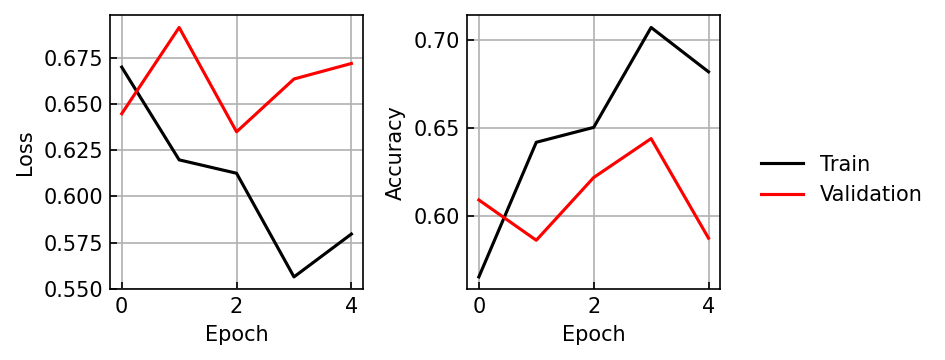

In [34]:
fig, ax = plt.subplots(1, 2, sharex=True, figsize=(5, 2.5))

ax[0].plot(model_stats[0], color='black', label='Train')
ax[0].plot(model_stats[2], color='red', label='Validation')
ax[0].set(xlabel='Epoch', ylabel='Loss')

ax[1].plot(model_stats[1], color='black', label='Train')
ax[1].plot(model_stats[3], color='red', label='Validation')
ax[1].set(xlabel='Epoch', ylabel='Accuracy')

fig.legend(*ax[1].get_legend_handles_labels(), 
           loc='center left', bbox_to_anchor=[1, 0.5], framealpha=0)

plt.tight_layout()

In [35]:
model.eval()
with torch.no_grad():
    test_correct_ = 0.
    for xb, yb, lengths in tqdm(test_loader,leave=False):
        xb = xb.to(device)
        yb = yb.to(device)
        y_pred = model(xb, lengths.cpu().numpy())
        y_pred = torch.argmax(y_pred, dim=1)
        test_correct_ += (y_pred == yb).float().sum().item()
    test_acc = test_correct_ / len(test_loader.dataset)

print(f"Test accuracy: {test_acc:.3f}")

  0%|          | 0/782 [00:00<?, ?it/s]

Test accuracy: 0.582


In [36]:
# Classify a single example
idx = np.random.choice(len(test_dataset))
sample = test_dataset[idx]
text = sample['text']
print('Comment:', text)
print()
print('True sentiment:', sample['label'])

# Convert comment with tokenizer, etc.
model.eval()
batch = collate_fn([sample,])
with torch.no_grad():
    y_pred = model(batch[0].to(device), batch[2])
    y_pred = F.softmax(y_pred, dim=1)

print('Predicted probability:', y_pred[0].cpu().numpy())

Comment: Being a "Wallace and Gromit-fan", I was looking forward for this full-length movie. Surprisingly I saw it at THE world-premiere in Vlissingen (NL), at the Film by the Sea festival. A wonderful feeling to be one of the first to see this very amusing and merry movie. It's about Wallace and Gromit (whom I believe don't need an introduction) having their own pest-control company in the city which is hosting a giant-vegetable contest in a few days. Everyone, including an eccentric baroness, is hoping his or her giant carrot or melon will win the Golden carrot. Unfortunately the town is plagued by lots of hungry rabbits. This is where W&G come in. The have their own cracking contraptions to control these cute creatures in a human way.<br /><br />It's a very funny and colorful story. Anyone who liked the three proceeding short movies of W&G (which are more than great!), will love this full-length movie. Nick Park really delivered a wonderful and original result with a great sense for

## Implementing an LSTM cell

In [ ]:
x_seq = torch.FloatTensor([[1,], [2,], [3,]])
x_seq = x_seq.repeat(1, 2)
print(f"x_seq has shape {x_seq.shape} which means it is a sequence of {x_seq.shape[0]} {x_seq.shape[1]}-dimensional vectors")

An LSTM has a hidden state $h^{(t)}$ and a cell state $c^{(t)}$.
It contains a set of **gating functions** that allow the model to input/update ($i^{(t)}$), forget ($f^{(t)}$), and output ($o^{(t)}$)

Each gate ($i^{(t)},f^{(t)},o^{(t)}$ each receive inputs from the previous hidden state $h^{(t-1)}$ and the current input $x^{(t)}$

The gating functions are given by
\begin{align}
    i^{(t)} &= \sigma\left( W_{ii} x^{(t)} + b_{ii} + W_{hi} h^{(t-1)} + b_{hi} \right) \\
    f^{(t)} &= \sigma\left( W_{if} x^{(t)} + b_{if} + W_{hf} h^{(t-1)} + b_{hf} \right) \\
    o^{(t)} &= \sigma\left( W_{io} x^{(t)} + b_{io} + W_{ho} h^{(t-1)} + b_{ho} \right) \\
\end{align}

There is also a cell input $g^{(t)}$
\begin{align}
    g^{(t)} &= \tanh \left( W_{ig} x^{(t)} + b_{ig} + W_{hg} h^{(t-1)} + b_{hg} \right) \\
\end{align}

The **cell state** $c^{(t)}$ uses the **forget gate** to determine whether to discard the previous cell state $c^{(t-1)}$ and the **input gate** to determine whether to accept the new input $g^{(t)}$

\begin{align}
    c^{(t)} &= f^{(t)} c^{(t-1)} + i^{(t)} g^{(t)}
\end{align}

The **hidden** state of the LSTM is then the product of the activated cell state and the output gate.
\begin{align}
    h^{(t)} &= o^{(t)} \tanh c^{(t)}
\end{align}

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class LSTM_Cell(nn.Module):
    def __init__(self, input_size=2, hidden_size=4):
        super().__init__()

        self.hidden_size = hidden_size

        # Input gate weight and biases
        self.w_ii = nn.Parameter(torch.randn(size=(hidden_size, input_size)))
        self.b_ii = nn.Parameter(torch.zeros(hidden_size))

        self.w_ih = nn.Parameter(torch.randn(size=(hidden_size, hidden_size)))
        self.b_ih = nn.Parameter(torch.zeros(hidden_size))

        # Forget gate weight and biases
        self.w_fi = nn.Parameter(torch.randn(size=(hidden_size, input_size)))
        self.b_fi = nn.Parameter(torch.zeros(hidden_size))

        self.w_fh = nn.Parameter(torch.randn(size=(hidden_size, hidden_size)))
        self.b_fh = nn.Parameter(torch.zeros(hidden_size))

        # Cell input weight and biases
        self.w_gi = nn.Parameter(torch.randn(size=(hidden_size, input_size)))
        self.b_gi = nn.Parameter(torch.zeros(hidden_size))

        self.w_gh = nn.Parameter(torch.randn(size=(hidden_size, hidden_size)))
        self.b_gh = nn.Parameter(torch.zeros(hidden_size))
        
        # Output gate weight and biases
        self.w_oi = nn.Parameter(torch.randn(size=(hidden_size, input_size)))
        self.b_oi = nn.Parameter(torch.zeros(hidden_size))

        self.w_oh = nn.Parameter(torch.randn(size=(hidden_size, hidden_size)))
        self.b_oh = nn.Parameter(torch.zeros(hidden_size))
        
    def forward(self, x):
        """ x has size [B, t, c]
        """
        B, T, C = x.shape

torch_LSTM = nn.LSTM(input_size=2, hidden_size=4, batch_first=True)
print("Ground truth")
print("------------")
output, (hidden, cell) = torch_LSTM(x_seq[None])
print(f"Output is of size {output.shape}")
print(output)
print()
print(f"Last hidden is of size {hidden.shape}")
print(hidden)
print()
print(f"Last cell is of size {cell.shape}")
print(cell)

print()
print("Our implementation")
print("------------------")
np.set_printoptions(precision=4)
lstm = LSTM_Cell()
with torch.no_grad():
    lstm.w_ii[:] = torch_LSTM.weight_ih_l0[0:4]
    lstm.b_ii[:] = torch_LSTM.bias_ih_l0[0:4]
    lstm.w_ih[:] = torch_LSTM.weight_hh_l0[0:4]
    lstm.b_ih[:] = torch_LSTM.bias_hh_l0[0:4]

    lstm.w_fi[:] = torch_LSTM.weight_ih_l0[4:8]
    lstm.b_fi[:] = torch_LSTM.bias_ih_l0[4:8]
    lstm.w_fh[:] = torch_LSTM.weight_hh_l0[4:8]
    lstm.b_fh[:] = torch_LSTM.bias_hh_l0[4:8]

    lstm.w_gi[:] = torch_LSTM.weight_ih_l0[8:12]
    lstm.b_gi[:] = torch_LSTM.bias_ih_l0[8:12]
    lstm.w_gh[:] = torch_LSTM.weight_hh_l0[8:12]
    lstm.b_gh[:] = torch_LSTM.bias_hh_l0[8:12]

    lstm.w_oi[:] = torch_LSTM.weight_ih_l0[12:16]
    lstm.b_oi[:] = torch_LSTM.bias_ih_l0[12:16]
    lstm.w_oh[:] = torch_LSTM.weight_hh_l0[12:16]
    lstm.b_oh[:] = torch_LSTM.bias_hh_l0[12:16]

output, (hidden, cell) = lstm(x_seq[None])

print()
print(f"Output is of size {output.shape}")
print(output)
print()
print(f"Last hidden is of size {hidden.shape}")
print(hidden)
print()
print(f"Last cell is of size {cell.shape}")
print(cell)

In [ ]:
import torch.nn.functional as F

class LSTM_Model(nn.Module):
    def __init__(self, vocab_size, embedding_dim, rnn_size, fc_size):
        super().__init__()

    def forward(self, text, lengths):


torch.manual_seed(42)
model = LSTM_Model(
    vocab_size=len(vocab),# tokenizer.vocab_size,
    embedding_dim=32,
    rnn_size=128,
    fc_size=128
)
model

In [ ]:
# Define a loss function and optimizer
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
model, model_stats = train(model, optimizer, loss, train_loader, val_loader, num_epochs=5)

In [ ]:
model.eval()
with torch.no_grad():
    test_correct_ = 0.
    for xb, yb, lengths in tqdm(test_loader,leave=False):
        xb = xb.to(device)
        yb = yb.to(device)
        y_pred = model(xb, lengths.cpu().numpy())
        y_pred = torch.argmax(y_pred, dim=1)
        test_correct_ += (y_pred == yb).float().sum().item()
    test_acc = test_correct_ / len(test_loader.dataset)

print(f"Test accuracy: {test_acc:.3f}")

In [ ]:
# Classify a single example
idx = np.random.choice(len(test_dataset))
sample = test_dataset[idx]
text = sample['text']
print('Comment:', text)
print()
print('True sentiment:', sample['label'])

# Convert comment with tokenizer, etc.
model.eval()
batch = collate_fn([sample,])
with torch.no_grad():
    y_pred = model(batch[0].to(device), batch[2])
    y_pred = F.softmax(y_pred, dim=1)

print('Predicted probability:', y_pred[0].cpu().numpy())